# Qian — LoRA crop and resolution experiments
Use the team's strongest **LoRA r24 + extras** recipe with the required IN21K→IN1K ViT-B/16. No VPT. Train on 1,000 classes with five images/class held out; fitting images alone build fresh prototypes at each resolution. The head remains 10,000-way with original labels. Classes outside the subset start with seeded random head rows; holdout and full-data prototypes are never used to initialize them.

| Arm | Resolution | Image preparation |
|---|---:|---|
| A | 336 | Current random crop |
| B | 336 | 75% current crop + 25% whole image with padding |
| C | 384 | Current random crop |
| D | 384 | 75% current crop + 25% whole image with padding |

Every image gets **one view per visit**. Flip, color changes, normalization, optimizer, seed, and LoRA settings stay the same. Choose an **A100 GPU runtime**. This notebook trains models; the CPU advice for the inspection notebook does not apply here.

Default: **12 training minutes per arm** (48 for A–D), plus extraction, prototypes, evaluation and saving. Optional E adds 12 minutes. Those other steps take additional wall time; this is not four 144-minute full-data runs. Training timing includes image loading and augmentation. Results shortlist candidates, not final full-data scores.


In [11]:
REPO_URL = "https://github.com/keaidewoq/cs604-project.git"
REPO_DIR = "/content/qq_lora_ablation_repo"
BRANCH = "qq_lora_ablation"  # Publish this branch before opening the launcher in Colab.
DATA_DIR = "/content/data"
DRIVE_OUT = "/content/drive/MyDrive/CS604_RUNS"
EXPERIMENT_NAME = "qq_lora_crop_resolution_c1000_seed42_v1"
CONFIG = "configs/qq_lora_ablation.yaml"
MINUTES_PER_ARM = 12
NUM_CLASSES_SUBSET = 1000
SEED = 42
NUM_WORKERS = 8
DOWNLOAD_DATA = True
RUN_OPTIONAL_448 = True  # Enable only after reviewing A–D.
# Keep the same name/settings to reuse completed arms. Change the name for a
# new seed or recipe. Interrupted arms are not silently resumed from partial weights.


## 1. Connect to GitHub
Same hidden-token connection as your training launcher. Checkout/pull `qq_lora_ablation`; this does not merge it with main.


In [2]:
import sys
import base64
import os
import subprocess
from getpass import getpass

# Pass credentials through a temporary child-process environment, not the URL.
token = getpass("GitHub PAT (hidden; repo scope). Leave empty for a public repo: ")
git_env = os.environ.copy()
if token:
    auth = base64.b64encode(f"x-access-token:{token}".encode()).decode()
    git_env.update(GIT_CONFIG_COUNT="1", GIT_CONFIG_KEY_0="http.extraHeader",
                   GIT_CONFIG_VALUE_0=f"Authorization: Basic {auth}")
    del auth
try:
    if os.path.isdir(os.path.join(REPO_DIR, ".git")):
        subprocess.run(["git", "-C", REPO_DIR, "remote", "set-url", "origin", REPO_URL], check=True)
        subprocess.run(["git", "-C", REPO_DIR, "fetch", "origin"], env=git_env, check=True)
        subprocess.run(["git", "-C", REPO_DIR, "checkout", BRANCH], check=True)
        subprocess.run(["git", "-C", REPO_DIR, "pull", "--ff-only", "origin", BRANCH], env=git_env, check=True)
    else:
        subprocess.run(["git", "clone", "--branch", BRANCH, REPO_URL, REPO_DIR], env=git_env, check=True)
finally:
    del token, git_env
os.chdir(REPO_DIR)
actual = subprocess.check_output(["git", "branch", "--show-current"], text=True).strip()
assert actual == BRANCH, f"Wrong branch: {actual}"
print("Branch:", actual)
print("Commit:", subprocess.check_output(["git", "rev-parse", "--short", "HEAD"], text=True).strip())

if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)


GitHub PAT (hidden; repo scope). Leave empty for a public repo: ··········
Branch: qq_lora_ablation
Commit: 0f45c08


## 2. Install packages and check the GPU


In [3]:
subprocess.run([sys.executable, "-m", "pip", "install", "-r", "requirements.txt"], check=True)
import torch
assert torch.cuda.is_available(), "Select a GPU runtime; A100 is recommended."
print("GPU:", torch.cuda.get_device_name())
print("VRAM (GiB):", round(torch.cuda.get_device_properties(0).total_memory / 2**30, 1))
if 'A100' not in torch.cuda.get_device_name():
    print("For comparable timing, run all arms on the same A100. Do not mix hardware between arms.")


GPU: NVIDIA A100-SXM4-40GB
VRAM (GiB): 39.5


## 3. Mount Drive
Use the same `CS604_RUNS` shared-folder shortcut as before. Dataset images stay on temporary Colab storage; results and checkpoint files go to Drive.


In [4]:
from pathlib import Path
from google.colab import drive
drive.mount("/content/drive")
base_out = Path(DRIVE_OUT)
if not base_out.is_dir():
    raise FileNotFoundError(f"{DRIVE_OUT} not found. Add the shared CS604_RUNS folder as a shortcut in My Drive.")
EXPERIMENT_DIR = base_out / EXPERIMENT_NAME
EXPERIMENT_DIR.mkdir(parents=True, exist_ok=True)
print("Experiment:", EXPERIMENT_DIR)


Mounted at /content/drive
Experiment: /content/drive/MyDrive/CS604_RUNS/qq_lora_crop_resolution_c1000_seed42_v1


## 4. Download or reuse extracted images
The full download/extraction can be slow and needs room for archives plus images. Check disk space first. Set `DOWNLOAD_DATA=False` to use an existing extract. Reuse is based on a small path check; it does not certify every file.


In [5]:
# Stream subprocess output into the notebook, and stop on failure.
def run_live(command):
    process = subprocess.Popen(command, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                               text=True, bufsize=1)
    try:
        for line in process.stdout:
            print(line, end="", flush=True)
        returncode = process.wait()
        if returncode:
            raise subprocess.CalledProcessError(returncode, command)
    except BaseException:
        if process.poll() is None:
            process.terminate()
        process.wait()
        raise


import shutil
root = Path(DATA_DIR)
root.mkdir(parents=True, exist_ok=True)
print(f"Free Colab disk: {shutil.disk_usage(root).free / 2**30:.1f} GiB")
def extracted_training_available():
    listing = root / 'train.txt'
    if not listing.is_file(): return False
    paths = []
    with listing.open() as handle:
        for line in handle:
            if line.strip(): paths.append(line.split()[0])
            if len(paths) == 20: break
    return bool(paths) and all((root / path).is_file() for path in paths)
if DOWNLOAD_DATA and not extracted_training_available():
    run_live([sys.executable, '-u', 'scripts/download_data.py', '--dest', DATA_DIR])
else:
    print('Using existing dataset:', root)
assert (root / 'train.txt').is_file(), 'Set DATA_DIR to the extracted training dataset.'


Free Colab disk: 193.3 GiB
[download] snapshot doem1997/cs604-course-data -> /content/data

Fetching 7 files:   0%|          | 0/7 [00:00<?, ?it/s]Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.

Fetching 7 files: 100%|██████████| 7/7 [02:02<00:00, 17.52s/it]
[download] extracting train.tar.gz
/content/qq_lora_ablation_repo/scripts/download_data.py:36: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tf.extractall(root)
[download] extracting val.tar.gz
[download] ready at /content/data


## 5. Review settings before training
Each arm starts from the original pretrained backbone, not another arm's checkpoint. A/B share 336 fit-only prototypes; C/D share separately built 384 prototypes. Evaluation uses the same **center crop 0.9**, without flip or zoom. We compare **final accuracy after equal training minutes**; best-epoch accuracy is recorded for reference.

Both crop branches still receive the existing flip and color jitter. The padded branch resizes the whole image without stretching, then adds borders filled with the model's mean color. Full-image views can preserve complete subjects but also make small ones smaller.

This subset uses a smaller fraction of the available classes, so its scores are not comparable to full-data CodaBench results. The shared trainer uses a 5% time warmup and cosine decay to the end of each arm's budget, with no epoch ceiling.


In [6]:
from src.utils import load_config
cfg = load_config(CONFIG)
print("Backbone:", cfg.model_name)
print("LoRA rank:", cfg.lora_rank, "targets:", cfg.lora_targets)
print("Extra trainable parts:", cfg.unfreeze_extra)
print("Classifier:", cfg.head_type, "initialized from fit-only prototypes")
print("LoRA / head LR:", cfg.lr, cfg.head_lr)
print("Batch / accumulation:", cfg.batch_size, cfg.grad_accum_steps)
print("Fitting classes:", NUM_CLASSES_SUBSET, "holdout/class:", cfg.ablation_holdout)
print("Minutes per arm:", MINUTES_PER_ARM, "A–D total:", MINUTES_PER_ARM * 4)
print("Optional E adds:", MINUTES_PER_ARM, "training minutes")
print("Additional wall time is needed for prototypes, evaluation, loading weights and saving.")
assert 0 < MINUTES_PER_ARM <= 144
assert cfg.model_name == 'vit_base_patch16_224.augreg2_in21k_ft_in1k'
assert cfg.lora_rank == 24 and cfg.prompt_length == 0


Backbone: vit_base_patch16_224.augreg2_in21k_ft_in1k
LoRA rank: 24 targets: ['qkv', 'proj', 'fc1', 'fc2']
Extra trainable parts: ['norm', 'bias', 'pos_embed', 'cls_token']
Classifier: cosine initialized from fit-only prototypes
LoRA / head LR: 0.0003 0.003
Batch / accumulation: 128 2
Fitting classes: 1000 holdout/class: 5
Minutes per arm: 12 A–D total: 48
Optional E adds: 12 training minutes
Additional wall time is needed for prototypes, evaluation, loading weights and saving.


## 6. Run A–D
This runs sequentially and saves each completed arm immediately. Completed arms are reused only if settings, fitting/holdout lists, code, package versions and saved checkpoints match. If an arm was interrupted, use a new experiment name rather than silently mixing partial and full runs. Keep the same Colab runtime/hardware for a fair speed comparison.


In [7]:
command = [sys.executable, '-u', '-m', 'src.qq_lora_ablation',
           '--config', CONFIG, '--data_root', DATA_DIR, '--output_dir', str(EXPERIMENT_DIR),
           '--minutes', str(MINUTES_PER_ARM), '--classes', str(NUM_CLASSES_SUBSET),
           '--seed', str(SEED), '--workers', str(NUM_WORKERS)]
run_live(command + ['--stage', 'main'])


Streaming output truncated to the last 5000 lines.
epoch 2 (time budget): 100%|██████████| 312/312 [02:28<00:00,  2.11it/s, loss=2.0017, lr=2.05e-04]
[epoch 2] train_loss=1.8751 val_loss=1.7415 val_acc=0.8908
[epoch 2] new best val_acc=0.8908

epoch 3 (time budget): 100%|██████████| 312/312 [02:28<00:00,  2.10it/s, loss=1.7123, lr=1.04e-04]
[epoch 3] train_loss=1.7060 val_loss=1.7149 val_acc=0.8984
[epoch 3] new best val_acc=0.8984

epoch 4 (time budget): 100%|██████████| 312/312 [02:29<00:00,  2.09it/s, loss=1.6976, lr=2.41e-05]
[epoch 4] train_loss=1.6324 val_loss=1.7120 val_acc=0.9046
[epoch 4] new best val_acc=0.9046

epoch 5 (time budget):  84%|████████▍ | 262/312 [02:05<00:23,  2.09it/s, loss=1.4611, lr=0.00e+00]
[epoch 5] train_loss=1.5932 val_loss=1.7176 val_acc=0.9058
[epoch 5] new best val_acc=0.9058
[train] time limit reached after 12.01 training minutes
[end] trainable=11.78M/97.31M (12.11%) wall_s=780.7 gpu_hours=0.2169 peak_vram_gb=25.088
[train] done. checkpoints in /con

## 7. Review the four results
Accuracy is shown as a percentage; speed includes training-time image loading. Compare B−A and D−C for crop effects, and C−A and D−B for resolution effects. A result from one seed can be noisy; repeat promising comparisons with another seed before a full-data run.


,arm,resolution,full_image_probability,final_val_acc,best_val_acc,training_minutes,epochs,images_per_second,peak_vram_gib,adaptation_pct
0,A,336,0.00,0.9082,0.9084,12.005667,6.282051,348.279979,19.399045,4.653365
1,B,336,0.25,0.9058,0.9064,12.002833,6.237179,345.873891,19.397477,4.653365
2,C,384,0.00,0.9058,0.9058,12.005167,4.839744,268.328914,25.088410,4.768192
3,D,384,0.25,0.9094,0.9106,12.000500,4.868590,270.033193,25.089697,4.768192


Padding at 336: -0.24 percentage points
Padding at 384: +0.36 percentage points
Resolution with crops: -0.24 percentage points
Resolution with mixed views: +0.36 percentage points


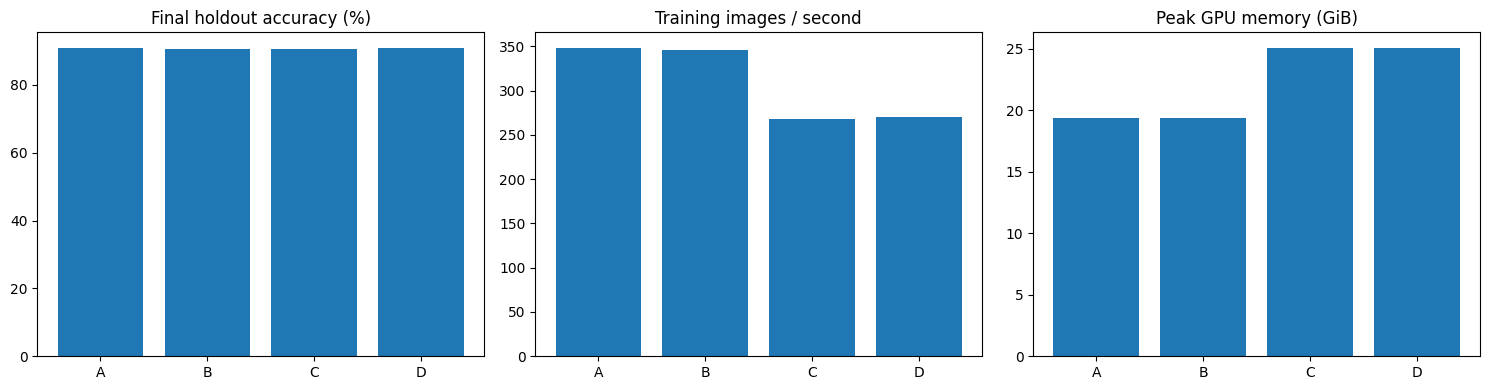

384 has not beaten the best 336 score by more than 0.3 percentage points. Keep 448 off for now.


In [8]:
import json
import pandas as pd
import matplotlib.pyplot as plt
results = pd.read_csv(EXPERIMENT_DIR / 'results.csv')
display(results[['arm','resolution','full_image_probability','final_val_acc','best_val_acc',
                 'training_minutes','epochs','images_per_second','peak_vram_gib','adaptation_pct']])
main_results = results[results.arm.isin(['A','B','C','D'])].set_index('arm')
for label,left,right in [('Padding at 336','B','A'),('Padding at 384','D','C'),
                         ('Resolution with crops','C','A'),('Resolution with mixed views','D','B')]:
    delta = 100*(main_results.loc[left,'final_val_acc']-main_results.loc[right,'final_val_acc'])
    print(f'{label}: {delta:+.2f} percentage points')
fig,axes = plt.subplots(1,3,figsize=(15,4))
for ax,field,title in zip(axes,['final_val_acc','images_per_second','peak_vram_gib'],['Final holdout accuracy (%)','Training images / second','Peak GPU memory (GiB)']):
    values = results[field]*100 if field=='final_val_acc' else results[field]
    ax.bar(results.arm,values); ax.set_title(title)
fig.tight_layout(); fig.savefig(EXPERIMENT_DIR/'comparison.png',dpi=150); plt.show()
selection = json.loads((EXPERIMENT_DIR/'selection.json').read_text())
if selection['candidate_384']:
    print('384 candidate for optional 448 comparison:', selection['candidate_384']['arm'])
else:
    print('384 has not beaten the best 336 score by more than 0.3 percentage points. Keep 448 off for now.')


## 8. Optional: compare the better 384 setting with 448
Set `RUN_OPTIONAL_448=True` in Settings, rerun that settings cell, then run this cell. **It adds one fresh 448 arm; it reuses the completed 384 arm.** The crop choice, fitting/holdout images, optimizer and training minutes match. Prototypes are freshly built at 448 from fitting images only.

To avoid spending time on a tiny apparent gain, this runs only if the best 384 arm exceeds the best 336 arm by more than **0.3 percentage points**. This is a screening rule, not a statistical guarantee. No 448 run starts if A–D are missing. Rerunning the results cell above includes E.


In [13]:
if RUN_OPTIONAL_448:
    from pathlib import Path
    from src.utils import load_config
    from src.qq_lora_ablation import run_arm, save_results, write_json

    root = Path(EXPERIMENT_DIR).resolve()
    records = pd.read_csv(root / 'results.csv').to_dict('records')

    # Choose the highest-scoring completed 384 arm.
    selected = max(
        (r for r in records if r['resolution'] == 384),
        key=lambda r: r['final_val_acc'],
    )

    # Reuse its exact training settings and fitting/holdout split.
    cfg = load_config(Path(selected['run_dir']) / 'config.yaml')
    split = Path(cfg.data_root)
    assert (split / 'train.txt').exists(), (
        'Local split is missing. Rerun A–D setup to recreate it.'
    )

    print(
        f"Testing 448 against arm {selected['arm']} "
        f"({selected['final_val_acc']:.2%}), bypassing the gain threshold."
    )

    e = run_arm(
        cfg, split, root,
        'E_448', 448, selected['full_image_probability'],
    )

    records = [r for r in records if r['arm'] != 'E_448'] + [e]
    save_results(root, records)

    selection = json.loads((root / 'selection.json').read_text())
    selection.update(candidate_384=selected, forced_448=True)
    write_json(root / 'selection.json', selection)

    comparison = pd.DataFrame([selected, e])
    display(comparison[[
        'arm', 'resolution', 'full_image_probability',
        'final_val_acc', 'training_minutes', 'epochs',
        'images_per_second', 'peak_vram_gib',
    ]])

    gain = 100 * (e['final_val_acc'] - selected['final_val_acc'])
    print(f"448 minus matched 384: {gain:+.2f} percentage points")
else:
    print('Set RUN_OPTIONAL_448 = True to run the 448 comparison.')


Testing 448 against arm D (90.94%), bypassing the gain threshold.


Fit-only prototypes 448: 100%|██████████| 313/313 [01:35<00:00,  3.27it/s]


[train] device=cuda method=lora model=vit_base_patch16_224.augreg2_in21k_ft_in1k
[train] run_dir=/content/drive/.shortcut-targets-by-id/107nc4GKekmaKe38GR_8VBn3Bh_xH-ZtR/CS604_RUNS/qq_lora_crop_resolution_c1000_seed42_v1/E_448/lora_20261018_093724
[lora] wrapped 48 layers (qkv, proj, fc1, fc2 in 12 blocks), rank=24, alpha=24.0, dropout=0.0: 3,538,944 params
[unfreeze_extra] norm, bias, pos_embed, cls_token: 725,760 params
[params] backbone trainable 4.26M/86.25M (4.94%, head excluded)
[head] loaded prototypes from /content/drive/.shortcut-targets-by-id/107nc4GKekmaKe38GR_8VBn3Bh_xH-ZtR/CS604_RUNS/qq_lora_crop_resolution_c1000_seed42_v1/prototypes_fit_448.pt  shape=(10000, 768)
[optim] backbone lr=0.0003  head_lr=0.003
[train] images=40000, batches_per_epoch=312, batch_size=128, workers=8
[train] GPU=NVIDIA A100-SXM4-40GB
[train] stopping=training-time budget only
[start] trainable=11.94M/97.47M (12.25%) wall_s=1.6 gpu_hours=0.0004 peak_vram_gb=3.263
[train] training-only time limit=12.

epoch 1 (time budget): 100%|██████████| 312/312 [03:26<00:00,  1.51it/s, loss=2.2780, lr=2.56e-04]


[epoch 1] train_loss=2.3854 val_loss=1.7759 val_acc=0.8788
[epoch 1] new best val_acc=0.8788


epoch 2 (time budget): 100%|██████████| 312/312 [03:26<00:00,  1.51it/s, loss=1.7669, lr=1.26e-04]


... (3 outputs left out)

epoch 4 (time budget):  48%|████▊     | 150/312 [01:40<01:48,  1.49it/s, loss=1.5643, lr=0.00e+00]


[epoch 4] train_loss=1.5824 val_loss=1.6942 val_acc=0.9122
[train] time limit reached after 12.01 training minutes
[end] trainable=11.94M/97.47M (12.25%) wall_s=786.0 gpu_hours=0.2183 peak_vram_gb=33.901
[train] done. checkpoints in /content/drive/.shortcut-targets-by-id/107nc4GKekmaKe38GR_8VBn3Bh_xH-ZtR/CS604_RUNS/qq_lora_crop_resolution_c1000_seed42_v1/E_448/lora_20261018_093724

Final holdout scores (same training minutes; no zoom/flip):
A: 336 pad=0% acc=0.9082 epochs=6.28 speed=348.3 img/s VRAM=19.40 GiB
B: 336 pad=25% acc=0.9058 epochs=6.24 speed=345.9 img/s VRAM=19.40 GiB
C: 384 pad=0% acc=0.9058 epochs=4.84 speed=268.3 img/s VRAM=25.09 GiB
D: 384 pad=25% acc=0.9094 epochs=4.87 speed=270.0 img/s VRAM=25.09 GiB
E_448: 448 pad=25% acc=0.9122 epochs=3.48 speed=192.9 img/s VRAM=33.90 GiB


,arm,resolution,full_image_probability,final_val_acc,training_minutes,epochs,images_per_second,peak_vram_gib
0,D,384,0.25,0.9094,12.0005,4.868590,270.033193,25.089697
1,E_448,448,0.25,0.9122,12.0090,3.480769,192.921975,33.900936


448 minus matched 384: +0.28 percentage points


## 9. Training curves and what to do next
Each arm folder contains its resolved config, best/last checkpoints and normal training logs. `results.csv` records final/best accuracy, training minutes, wall minutes, completed epochs, speed, peak memory and the backbone adaptation percentage (classifier excluded). Fitting/holdout lists are copied into `split_manifests/` on Drive; image links stay on temporary Colab disk.

Choose a promising setting only if the gain is worth its speed and memory cost. Repeat close comparisons with another seed, using a new experiment name. A final full-data run would need **fresh all-data prototypes and pretrained weights**, all 450,000 images and a separate 144-minute budget. This notebook does not automatically launch that run or generate official submissions. Model-guided zoom can be tested afterward.


In [ ]:
for row in pd.read_csv(EXPERIMENT_DIR/'results.csv').itertuples(index=False):
    run_live([sys.executable,'scripts/plot_curves.py','--run_dir',row.run_dir,
              '--out_dir',str(EXPERIMENT_DIR / row.arm / 'plots')])
print('Saved results:', EXPERIMENT_DIR)
